# TORCS Training and Validation Tracks - Visualizing the Curvature

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm

from gym_torcs.curvature import RacingLineCurvatureMap
from gym_torcs.constants import MAX_CURVATURE, RACING_LINE_DIR

from scripts.configs import TRAIN_TRACKS, VAL_TRACKS

In [ ]:
# Same split as the experiment (scripts/configs.py), training tracks first.
TRACKS = [(t.name, "Training") for t in TRAIN_TRACKS] + [(t.name, "Validation") for t in VAL_TRACKS]
N_COLS = 6

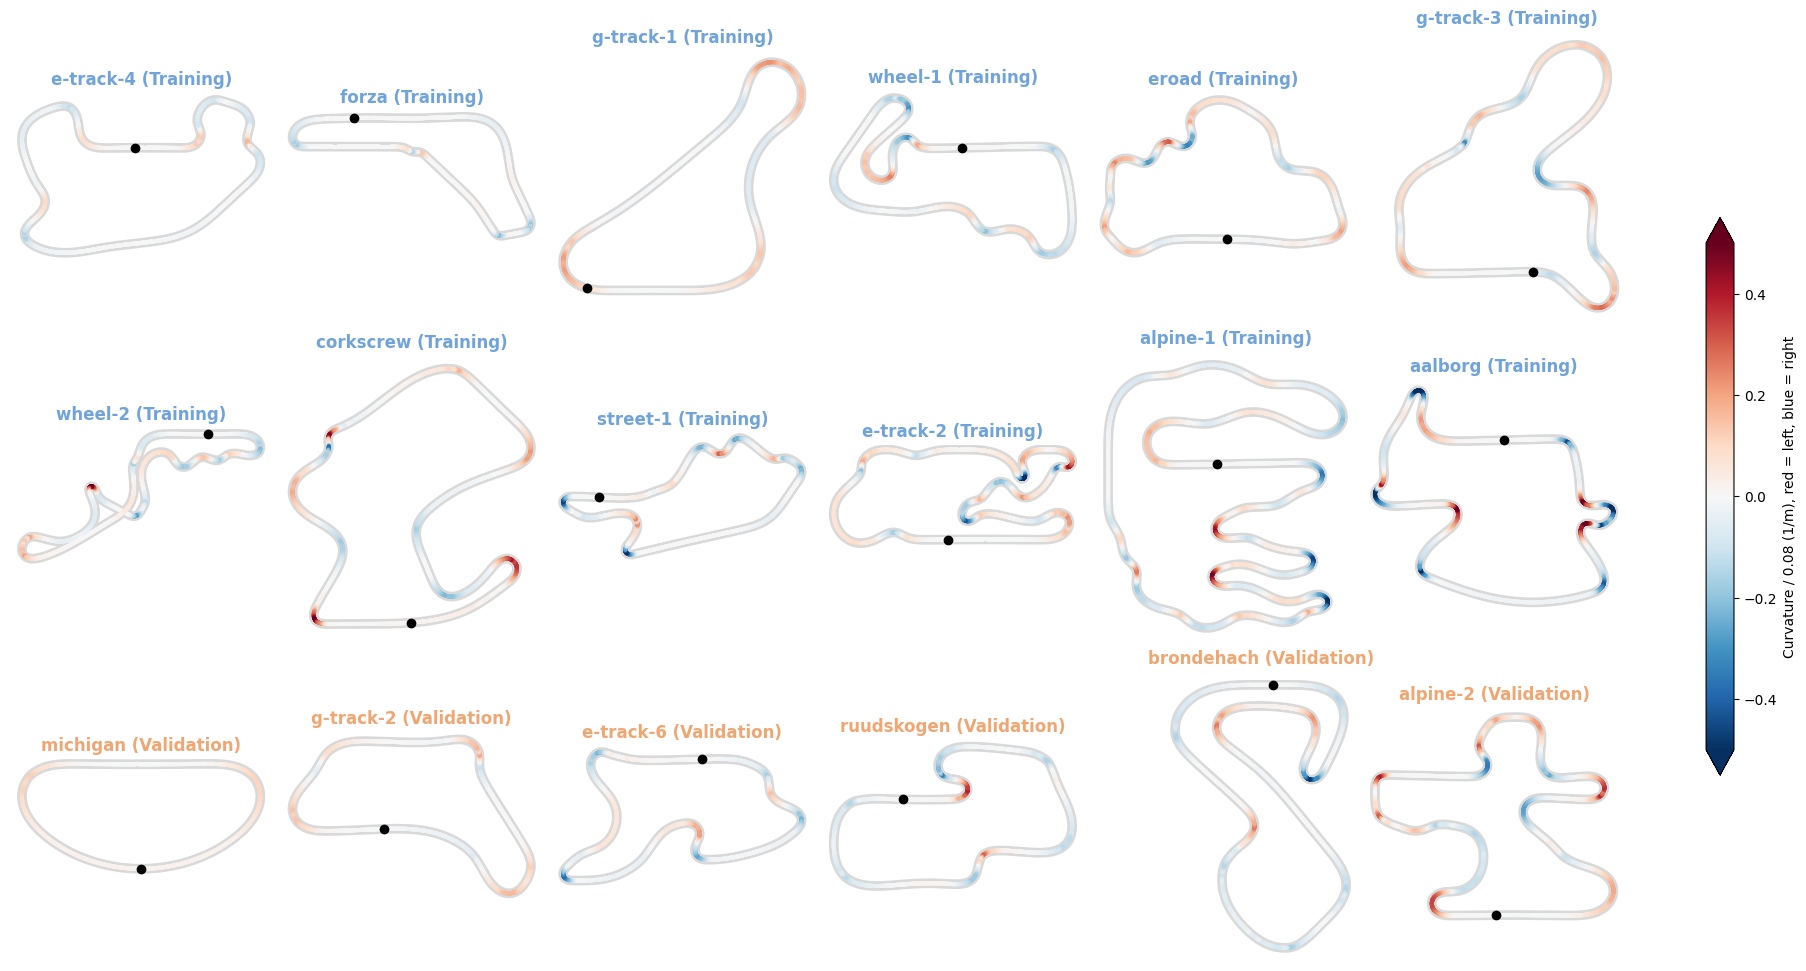

: 

In [ ]:
n_rows = -(-len(TRACKS) // N_COLS)
fig, axes = plt.subplots(nrows=n_rows, ncols=N_COLS, figsize=(3 * N_COLS, 3.2 * n_rows), layout="constrained")
# Curvature is signed (left vs. right turns), so use a diverging map centred at 0 and the same
# scale for every track. Values are normalised by MAX_CURVATURE as in the env. The scale ends at
# +-0.5 (25 m radius) so ordinary corners get strong colors; tighter hairpins saturate.
norm = TwoSlopeNorm(vmin=-0.5, vcenter=0.0, vmax=0.5)

for ax in axes.flat:
    ax.set_aspect("equal")
    ax.axis("off")

lines = None
for (track_name, split), ax in zip(TRACKS, axes.flat):
    ax.set_title(f"{track_name} ({split})", color="#6FA3D9" if split == "Training" else "#F0A672", fontweight="semibold")

    path = RACING_LINE_DIR / f"{track_name}.csv"
    if not path.exists():
        ax.text(0.5, 0.5, f"missing {path.name}", ha="center", va="center", transform=ax.transAxes)
        continue

    line = RacingLineCurvatureMap.from_csv(path)
    points = np.column_stack([line.x, line.y])
    segments = np.stack([points, np.roll(points, -1, axis=0)], axis=1)   # closed loop

    # Grey track underneath, racing line on top, colored by curvature.
    ax.plot(*np.vstack([points, points[:1]]).T, color="0.85", lw=7, solid_capstyle="round", zorder=1)
    lines = LineCollection(segments, cmap="RdBu_r", norm=norm, linewidths=3, capstyle="round", zorder=2)
    lines.set_array(line.curvature / MAX_CURVATURE)
    ax.add_collection(lines)
    ax.autoscale_view()

    # Mark the start/finish line.
    ax.plot(line.x[0], line.y[0], marker="o", color="black", markersize=6, zorder=3)

if lines is not None:
    cbar = fig.colorbar(lines, ax=axes, shrink=0.6, extend="both")
    cbar.set_label(f"Curvature / {MAX_CURVATURE} (1/m), red = left, blue = right")

plt.show()